# XFeat 8-bin descriptor experiments (2026-09-29)

Frozen XFeat (64-D), three original baselines (float cosine, fixed 8-bin quantile + ABS, learned thresholds + ABS), then an identity-initialized 64×64 projection trained with fixed edges. Training/calibration uses a deterministic subset of COCO val2017 images by default. The internal check uses synthetic warps of held-out COCO images; the final check uses **actual HPatches viewpoint/illumination photo pairs with the provided homographies**, completely separate from COCO.

Run all cells from the top. The COCO archive is about 1 GB and the HPatches full sequence archive about 1.3 GB. Both ZIP files are cached under `MyDrive/Colab Notebooks/CSE527_datasets` and reused across Colab sessions; only selected images are read from each ZIP. Google Drive mount authorization is requested on first run. For personal photos choose `DATA_SOURCE = 'upload'`.


In [1]:
!pip -q install opencv-python-headless numba

import time
import io
import zipfile
import subprocess
import shutil
from pathlib import Path
import cv2
import numpy as np
import torch
import torch.nn as nn
import torch.nn.functional as F
import matplotlib.pyplot as plt
from numba import njit, prange
from google.colab import files, drive

SEED = 7
TOP_K = 800
LEVELS = 8  # seven thresholds per descriptor dimension
TRAIN_WARPS_PER_IMAGE = 6
VALIDATION_WARPS_PER_IMAGE = 3
MAX_POSITIVES_PER_PAIR = 500
GEOMETRIC_THRESHOLD = 3.0
TRAIN_STEPS = 350
BATCH_SIZE = 128
LEARNING_RATE = 1e-3
SOFT_START_TEMPERATURE = 0.04
SOFT_END_TEMPERATURE = 0.012
DISTANCE_TEMPERATURE = 8.0
RANK_MARGIN = 2.0
ANCHOR_WEIGHT = 0.10
GAP_WEIGHT = 0.10
MIN_GAP = 0.003

torch.manual_seed(SEED)
np.random.seed(SEED)
rng = np.random.default_rng(SEED)
device = 'cuda' if torch.cuda.is_available() else 'cpu'

xfeat = torch.hub.load('verlab/accelerated_features', 'XFeat', pretrained=True, top_k=TOP_K).to(device).eval()
for parameter in xfeat.parameters():
    parameter.requires_grad_(False)
print('Device:', device)
# COCO is used for calibration/training and an internal synthetic-warp check.
# HPatches is reserved for the external real-photo evaluation at the end.
DATA_SOURCE = 'coco'  # change to 'upload' to use your own JPG/PNG files
COCO_SOURCE_COUNT = 24
COCO_URL = 'http://images.cocodataset.org/zips/val2017.zip'
drive.mount('/content/drive')
data_dir = Path('/content/drive/MyDrive/Colab Notebooks/CSE527_datasets')
data_dir.mkdir(parents=True, exist_ok=True)
print('Persistent dataset cache:', data_dir)

def download_archive(url, destination):
    if destination.exists() and zipfile.is_zipfile(destination):
        print('Using persistent Drive cache:', destination)
        return
    # Reuse a download from an earlier run in this same Colab session, if present.
    legacy = Path('/content/xfeat_data') / destination.name
    if legacy.exists() and zipfile.is_zipfile(legacy):
        shutil.copy2(legacy, destination)
        print('Copied previous runtime download into Drive:', destination)
        return
    print('Downloading once into Drive:', url)
    subprocess.run(['wget', '-q', '--show-progress', '-c', '-O', str(destination), url], check=True)
    if not zipfile.is_zipfile(destination):
        raise RuntimeError(f'Incomplete or invalid ZIP: {destination}. Delete it and rerun this cell.')

if DATA_SOURCE == 'coco':
    coco_zip = data_dir / 'val2017.zip'
    download_archive(COCO_URL, coco_zip)
    with zipfile.ZipFile(coco_zip) as archive:
        names = sorted(n for n in archive.namelist() if n.lower().endswith(('.jpg', '.jpeg', '.png')))
        if len(names) < COCO_SOURCE_COUNT:
            raise RuntimeError('COCO archive has fewer images than requested.')
        selected = np.random.default_rng(SEED).choice(len(names), COCO_SOURCE_COUNT, replace=False)
        image_items = [(Path(names[i]).name, archive.read(names[i])) for i in selected]
    print(f'Selected {len(image_items)} COCO images using seed {SEED}; no COCO annotations needed.')
elif DATA_SOURCE == 'upload':
    print('Upload JPG/PNG images from distinct scenes.')
    uploaded = files.upload()
    image_items = list(uploaded.items())
    if not image_items:
        raise ValueError('Upload at least one image.')
else:
    raise ValueError("DATA_SOURCE must be 'coco' or 'upload'")

def decode_and_resize(raw_bytes, maximum_side=640):
    image = cv2.imdecode(np.frombuffer(raw_bytes, np.uint8), cv2.IMREAD_COLOR)
    if image is None:
        raise ValueError('An uploaded file is not a readable JPG/PNG image.')
    height, width = image.shape[:2]
    scale = min(1.0, maximum_side / max(height, width))
    new_width = max(64, (int(width * scale) // 32) * 32)
    new_height = max(64, (int(height * scale) // 32) * 32)
    return cv2.resize(image, (new_width, new_height))

# Split by source image, before any synthetic warps or descriptor calibration.
# Upload images of distinct scenes; near-duplicate photos belong to the same split.
image_items = sorted(image_items)
images = [decode_and_resize(raw) for _, raw in image_items]
if len(images) >= 2:
    split_rng = np.random.default_rng(SEED)
    order = split_rng.permutation(len(images))
    validation_count = max(1, int(np.ceil(0.25 * len(images))))
    validation_ids = set(order[:validation_count].tolist())
    training_images = [im for i, im in enumerate(images) if i not in validation_ids]
    validation_images = [im for i, im in enumerate(images) if i in validation_ids]
    print('Training files:', [name for i, (name, _) in enumerate(image_items) if i not in validation_ids])
    print('Held-out files:', [name for i, (name, _) in enumerate(image_items) if i in validation_ids])
else:
    training_images = validation_images = images
    print('WARNING: One source image only; validation shares scene content with training.')
print('Training images:', len(training_images), 'Validation images:', len(validation_images))

The repository verlab_accelerated_features does not belong to the list of trusted repositories and as such cannot be downloaded. Do you trust this repository and wish to add it to the trusted list of repositories (y/N)?y
Downloading: "https://github.com/verlab/accelerated_features/zipball/main" to /root/.cache/torch/hub/main.zip
Downloading: "https://github.com/verlab/accelerated_features/raw/main/weights/xfeat.pt" to /root/.cache/torch/hub/checkpoints/xfeat.pt


100%|██████████| 5.96M/5.96M [00:00<00:00, 79.5MB/s]


Device: cpu
Mounted at /content/drive
Persistent dataset cache: /content/drive/MyDrive/Colab Notebooks/CSE527_datasets
Using persistent Drive cache: /content/drive/MyDrive/Colab Notebooks/CSE527_datasets/val2017.zip
Selected 24 COCO images using seed 7; no COCO annotations needed.
Training files: ['000000002261.jpg', '000000029675.jpg', '000000067534.jpg', '000000162858.jpg', '000000165713.jpg', '000000173008.jpg', '000000175364.jpg', '000000194506.jpg', '000000270402.jpg', '000000289343.jpg', '000000360097.jpg', '000000460841.jpg', '000000471869.jpg', '000000479596.jpg', '000000504711.jpg', '000000517832.jpg', '000000528524.jpg', '000000547383.jpg']
Held-out files: ['000000077595.jpg', '000000132544.jpg', '000000334006.jpg', '000000394559.jpg', '000000449432.jpg', '000000474039.jpg']
Training images: 18 Validation images: 6


In [2]:
def image_to_tensor(image):
    rgb = cv2.cvtColor(image, cv2.COLOR_BGR2RGB)
    return torch.from_numpy(rgb.copy()).permute(2, 0, 1).float()[None].to(device) / 255.0

@torch.inference_mode()
def extract_features(image):
    output = xfeat.detectAndCompute(image_to_tensor(image), top_k=TOP_K)[0]
    return {
        'keypoints': output['keypoints'].detach().cpu().float(),
        'descriptors': F.normalize(output['descriptors'].detach().cpu().float(), dim=-1),
    }

def make_random_homography(height, width, generator):
    center = (width / 2.0, height / 2.0)
    angle = generator.uniform(-20.0, 20.0)
    scale = generator.uniform(0.88, 1.08)
    affine = cv2.getRotationMatrix2D(center, angle, scale)
    affine[0, 2] += generator.uniform(-0.06, 0.06) * width
    affine[1, 2] += generator.uniform(-0.06, 0.06) * height
    homography = np.vstack([affine, [0., 0., 1.]]).astype(np.float32)
    homography[2, 0] = generator.uniform(-7e-5, 7e-5)
    homography[2, 1] = generator.uniform(-7e-5, 7e-5)
    return homography

def warp_image(image, homography, generator):
    height, width = image.shape[:2]
    warped = cv2.warpPerspective(image, homography, (width, height),
                                 flags=cv2.INTER_LINEAR, borderMode=cv2.BORDER_REFLECT)
    alpha = float(generator.uniform(0.82, 1.12))
    beta = float(generator.uniform(-12., 18.))
    return np.clip(warped.astype(np.float32) * alpha + beta, 0, 255).astype(np.uint8)

def project_points(points, homography):
    p = points.detach().cpu().numpy()
    p_h = np.concatenate([p, np.ones((len(p), 1), np.float32)], axis=1)
    projected = (homography @ p_h.T).T
    return torch.from_numpy((projected[:, :2] / projected[:, 2:3]).astype(np.float32))

def ground_truth_pairs(keypoints_1, keypoints_2, homography):
    if not len(keypoints_1) or not len(keypoints_2):
        return torch.empty(0, dtype=torch.long), torch.empty(0, dtype=torch.long)
    distances_12 = torch.cdist(project_points(keypoints_1, homography), keypoints_2)
    nearest_12 = distances_12.argmin(dim=1)
    errors = distances_12[torch.arange(len(keypoints_1)), nearest_12]
    distances_21 = torch.cdist(project_points(keypoints_2, np.linalg.inv(homography)), keypoints_1)
    nearest_21 = distances_21.argmin(dim=1)
    indices = torch.arange(len(keypoints_1))
    good = (nearest_21[nearest_12] == indices) & (errors < GEOMETRIC_THRESHOLD)
    return indices[good], nearest_12[good]

def build_pairs(source_images, warps_per_image, generator):
    pairs = []
    for image_index, image in enumerate(source_images):
        base = extract_features(image)
        for warp_index in range(warps_per_image):
            h = make_random_homography(*image.shape[:2], generator)
            warped = extract_features(warp_image(image, h, generator))
            i, j = ground_truth_pairs(base['keypoints'], warped['keypoints'], h)
            if len(i) > MAX_POSITIVES_PER_PAIR:
                keep = torch.randperm(len(i))[:MAX_POSITIVES_PER_PAIR]
                i, j = i[keep], j[keep]
            if len(i) < 32:
                print(f'Warning: image {image_index}, warp {warp_index}: {len(i)} positive pairs')
            pairs.append({'d1': base['descriptors'], 'd2': warped['descriptors'],
                          'k1': base['keypoints'], 'k2': warped['keypoints'],
                          'pos1': i, 'pos2': j, 'H': h})
    return pairs

start = time.perf_counter()
training_pairs = build_pairs(training_images, TRAIN_WARPS_PER_IMAGE, rng)
validation_pairs = build_pairs(validation_images, VALIDATION_WARPS_PER_IMAGE, rng)
training_batches = [(p['d1'][p['pos1']].contiguous(), p['d2'][p['pos2']].contiguous())
                    for p in training_pairs if len(p['pos1']) >= 32]
if not training_batches:
    raise RuntimeError('Too few geometric correspondences. Upload more textured images.')
calibration = torch.cat([torch.cat([p['d1'], p['d2']], dim=0) for p in training_pairs], dim=0)
if len(calibration) > 50000:
    calibration = calibration[torch.randperm(len(calibration))[:50000]]
print('Feature extraction time (training and validation):', round(time.perf_counter() - start, 2), 's')
print('Training pairs:', len(training_pairs), 'Validation pairs:', len(validation_pairs),
      'Calibration descriptors:', len(calibration))

Feature extraction time (training and validation): 23.31 s
Training pairs: 108 Validation pairs: 18 Calibration descriptors: 50000


step   0 | soft temp 0.0400 | loss 0.0280 | rank 0.0201 | margin 0.0158
step  50 | soft temp 0.0337 | loss 0.0232 | rank 0.0232 | margin 0.0000
step 100 | soft temp 0.0283 | loss 0.0777 | rank 0.0548 | margin 0.0458
step 150 | soft temp 0.0238 | loss 0.0480 | rank 0.0347 | margin 0.0265
step 200 | soft temp 0.0201 | loss 0.0250 | rank 0.0250 | margin 0.0000
step 250 | soft temp 0.0169 | loss 0.1445 | rank 0.0901 | margin 0.1088
step 300 | soft temp 0.0142 | loss 0.0325 | rank 0.0285 | margin 0.0079
step 349 | soft temp 0.0120 | loss 0.0562 | rank 0.0508 | margin 0.0107
Threshold training time: 2.62 s
Mean edge displacement: 0.01854732446372509


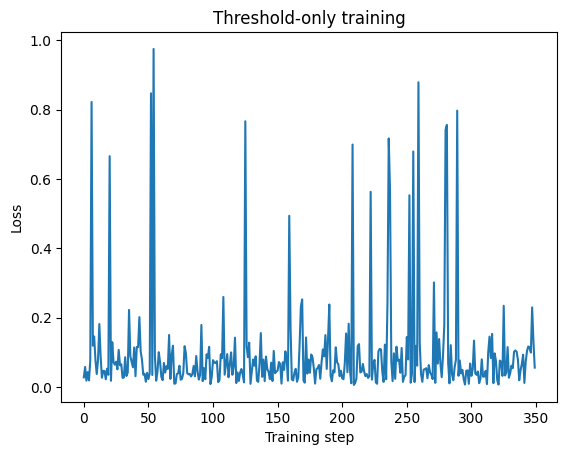

In [3]:
# This model contains only 64 x 7 learnable threshold values. No descriptor projection.
base_edges_cpu = torch.quantile(calibration, torch.arange(1, LEVELS).float() / LEVELS, dim=0).T.contiguous()

class Thresholds(nn.Module):
    def __init__(self, initial_edges):
        super().__init__()
        self.raw_edges = nn.Parameter(initial_edges.clone())

    def forward(self):
        # Ordered thresholds, so each dimension has exactly eight consecutive bins.
        return self.raw_edges.sort(dim=1).values

def soft_quantize(descriptors, edges, temperature):
    return torch.sigmoid((descriptors[:, :, None] - edges[None, :, :]) / temperature).sum(dim=-1)

def hard_quantize(descriptors, edges):
    return (descriptors[:, :, None] > edges[None, :, :]).sum(dim=-1).to(torch.uint8)

model = Thresholds(base_edges_cpu.to(device)).to(device)
base_edges = base_edges_cpu.to(device)
optimizer = torch.optim.Adam(model.parameters(), lr=LEARNING_RATE)
history = []
train_start = time.perf_counter()
for step in range(TRAIN_STEPS):
    pair_index = int(torch.randint(len(training_batches), (1,)).item())
    anchors_cpu, positives_cpu = training_batches[pair_index]
    take = torch.randperm(len(anchors_cpu))[:min(BATCH_SIZE, len(anchors_cpu))]
    anchors, positives = anchors_cpu[take].to(device), positives_cpu[take].to(device)
    temperature = SOFT_START_TEMPERATURE * (
        SOFT_END_TEMPERATURE / SOFT_START_TEMPERATURE
    ) ** (step / max(1, TRAIN_STEPS - 1))
    edges = model()
    qa = soft_quantize(anchors, edges, temperature)
    qb = soft_quantize(positives, edges, temperature)
    distances = torch.cdist(qa, qb, p=1)
    labels = torch.arange(len(anchors), device=device)
    logits = -distances / DISTANCE_TEMPERATURE
    rank_loss = (F.cross_entropy(logits, labels) + F.cross_entropy(logits.T, labels)) / 2
    diagonal = distances.diag()
    negatives = distances.masked_fill(torch.eye(len(anchors), device=device, dtype=torch.bool), float('inf'))
    margin_loss = (F.relu(diagonal - negatives.amin(dim=1) + RANK_MARGIN).mean()
                   + F.relu(diagonal - negatives.amin(dim=0) + RANK_MARGIN).mean()) / 2
    anchor_loss = (edges - base_edges).square().mean()
    gap_loss = F.relu(MIN_GAP - (edges[:, 1:] - edges[:, :-1])).square().mean()
    loss = rank_loss + 0.5 * margin_loss + ANCHOR_WEIGHT * anchor_loss + GAP_WEIGHT * gap_loss
    optimizer.zero_grad(set_to_none=True)
    loss.backward()
    optimizer.step()
    history.append((float(loss.detach()), float(rank_loss.detach()), float(margin_loss.detach())))
    if step % 50 == 0 or step == TRAIN_STEPS - 1:
        print(f'step {step:3d} | soft temp {temperature:.4f} | loss {history[-1][0]:.4f}'
              f' | rank {history[-1][1]:.4f} | margin {history[-1][2]:.4f}')

model.eval()
learned_edges_cpu = model().detach().cpu()
print('Threshold training time:', round(time.perf_counter() - train_start, 2), 's')
print('Mean edge displacement:', float((learned_edges_cpu - base_edges_cpu).abs().mean()))
plt.plot(np.asarray(history)[:, 0]); plt.xlabel('Training step'); plt.ylabel('Loss'); plt.title('Threshold-only training'); plt.show()

In [4]:
@njit(parallel=True, cache=False)
def pairwise_uint8_abs(code_1, code_2):
    out = np.empty((code_1.shape[0], code_2.shape[0]), np.uint16)
    for i in prange(code_1.shape[0]):
        for j in range(code_2.shape[0]):
            total = 0
            for k in range(code_1.shape[1]):
                a, b = int(code_1[i, k]), int(code_2[j, k])
                total += a - b if a >= b else b - a
            out[i, j] = total
    return out

def mutual_from_scores(scores, higher_is_better):
    if higher_is_better:
        nearest_12, nearest_21 = scores.argmax(axis=1), scores.argmax(axis=0)
    else:
        nearest_12, nearest_21 = scores.argmin(axis=1), scores.argmin(axis=0)
    indices = np.arange(scores.shape[0])
    keep = nearest_21[nearest_12] == indices
    return indices[keep], nearest_12[keep]

def encode(desc, edges):
    with torch.no_grad():
        levels = hard_quantize(desc.to(device), edges.to(device))
    return np.ascontiguousarray(levels.cpu().numpy(), dtype=np.uint8)

def match_float(pair):
    scores = (pair['d1'] @ pair['d2'].T).numpy()
    return mutual_from_scores(scores, higher_is_better=True)

def match_abs(pair, edges):
    a, b = encode(pair['d1'], edges), encode(pair['d2'], edges)
    return mutual_from_scores(pairwise_uint8_abs(a, b), higher_is_better=False)

def evaluate(name, matcher):
    total, correct, all_errors = 0, 0, []
    per_pair = []
    for pair in validation_pairs:
        i, j = matcher(pair)
        projected = project_points(pair['k1'][i], pair['H']).numpy()
        observed = pair['k2'][j].numpy()
        errors = np.linalg.norm(projected - observed, axis=1)
        right = int(np.count_nonzero(errors < GEOMETRIC_THRESHOLD))
        per_pair.append((len(i), right))
        total += len(i); correct += right; all_errors.extend(errors)
    precision = 100.0 * correct / total if total else 0.0
    median = float(np.median(all_errors)) if all_errors else float('nan')
    print(f'{name:>28}: mutual={total}, correct={correct}, precision={precision:.2f}%, median={median:.2f}px')
    return {'method': name, 'mutual': total, 'correct': correct,
            'precision': precision, 'median_px': median, 'per_pair': per_pair}

# Compile the Numba kernel outside the timing section.
_ = pairwise_uint8_abs(np.zeros((2, 64), np.uint8), np.zeros((2, 64), np.uint8))
results = [
    evaluate('XFeat float cosine', match_float),
    evaluate('Quantile edges + uint8 ABS', lambda p: match_abs(p, base_edges_cpu)),
    evaluate('Learned edges + uint8 ABS', lambda p: match_abs(p, learned_edges_cpu)),
]
print('Per-pair (mutual, correct):')
for index, values in enumerate(zip(*(r['per_pair'] for r in results))):
    print(' pair', index, values)

def benchmark(fn, warmup=3, repeats=12):
    for _ in range(warmup): fn()
    samples = []
    for _ in range(repeats):
        start = time.perf_counter_ns(); fn()
        samples.append((time.perf_counter_ns() - start) / 1e6)
    return float(np.median(samples))

timing_pair = validation_pairs[0]
for label, fn in [
    ('float cosine matching', lambda: match_float(timing_pair)),
    ('quantile encode + ABS matching', lambda: match_abs(timing_pair, base_edges_cpu)),
    ('learned encode + ABS matching', lambda: match_abs(timing_pair, learned_edges_cpu)),
]:
    print(f'{label}: median {benchmark(fn):.3f} ms (excludes XFeat extraction)')
print('Float descriptor: 256 bytes | uint8 bin-index descriptor: 64 bytes (4x smaller).')
print('A packed 3-bit code could theoretically use 24 bytes; this notebook measures uint8 storage and uint8 ABS.')

          XFeat float cosine: mutual=8178, correct=5598, precision=68.45%, median=1.37px
  Quantile edges + uint8 ABS: mutual=8075, correct=5405, precision=66.93%, median=1.41px
   Learned edges + uint8 ABS: mutual=7955, correct=5322, precision=66.90%, median=1.42px
Per-pair (mutual, correct):
 pair 0 ((476, 352), (471, 346), (469, 344))
 pair 1 ((432, 290), (428, 270), (425, 255))
 pair 2 ((447, 291), (437, 279), (423, 272))
 pair 3 ((416, 239), (410, 235), (397, 235))
 pair 4 ((423, 248), (425, 245), (417, 249))
 pair 5 ((441, 258), (436, 255), (429, 251))
 pair 6 ((419, 220), (405, 213), (409, 205))
 pair 7 ((448, 289), (447, 281), (444, 275))
 pair 8 ((397, 225), (394, 217), (389, 211))
 pair 9 ((446, 310), (435, 290), (428, 286))
 pair 10 ((432, 309), (433, 296), (424, 301))
 pair 11 ((467, 328), (455, 315), (445, 298))
 pair 12 ((476, 365), (472, 353), (461, 349))
 pair 13 ((471, 346), (470, 328), (460, 324))
 pair 14 ((491, 369), (493, 360), (482, 356))
 pair 15 ((500, 377), (48

In [5]:
# Optional: export the learned threshold model for use on new images.
# Both images must use these SAME edges. Never recalibrate on test pairs.
checkpoint_path = '/content/xfeat_learned_8bin_thresholds_2026-09-29.pt'
torch.save({'edges': learned_edges_cpu, 'baseline_quantile_edges': base_edges_cpu,
            'levels': LEVELS, 'descriptor_dimension': 64,
            'note': 'Frozen XFeat, per-dimension thresholds only; no projection.'}, checkpoint_path)
print('Checkpoint saved:', checkpoint_path)
print('To download it, run: files.download(checkpoint_path)')

Checkpoint saved: /content/xfeat_learned_8bin_thresholds_2026-09-29.pt
To download it, run: files.download(checkpoint_path)


## Next experiment: learn a 64×64 projection before fixed 8-bin coding

The XFeat model stays frozen. Initialize the projection as the identity matrix, learn it on training correspondences with **fixed training-only quantile boundaries**, then evaluate four methods on the **same held-out image pairs**: original float cosine, original fixed quantile + ABS, projected float cosine, and projected fixed quantile + ABS. The earlier learned-boundary result remains above for comparison.

The projection has no bias and retains 64 dimensions. The uint8 code is still 64 bytes; this experiment tests matching quality, not further storage reduction. Training uses differentiable soft bins, while evaluation uses hard bins. The fixed boundaries are computed only from training images and are never recalculated on the held-out images. Split by distinct source scenes, not by synthetic warp. Run the notebook from the top after changing the images.

projection step   0 | soft temp 0.0400 | loss 0.0326
projection step  50 | soft temp 0.0337 | loss 0.0906
projection step 100 | soft temp 0.0283 | loss 0.1088
projection step 150 | soft temp 0.0238 | loss 0.0234
projection step 200 | soft temp 0.0201 | loss 0.0735
projection step 250 | soft temp 0.0169 | loss 0.0514
projection step 300 | soft temp 0.0142 | loss 0.0132
projection step 349 | soft temp 0.0120 | loss 0.0557
Projection training time: 1.82 s
Mean |W - I|: 0.016948707401752472


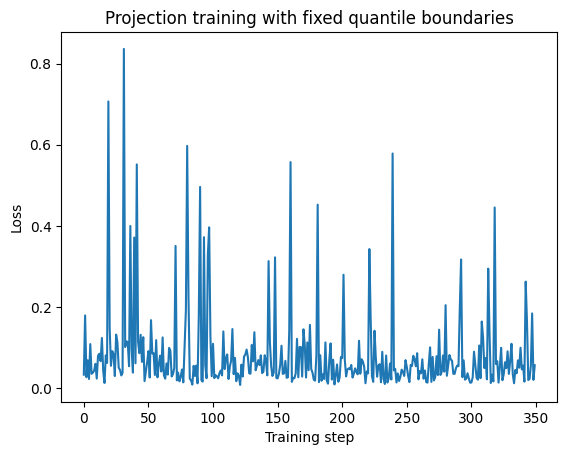

In [6]:
class LinearProjection(nn.Module):
    def __init__(self, dimensions=64):
        super().__init__()
        self.linear = nn.Linear(dimensions, dimensions, bias=False)
        nn.init.eye_(self.linear.weight)

    def forward(self, descriptors):
        return F.normalize(self.linear(descriptors), dim=-1)

projection = LinearProjection(calibration.shape[1]).to(device)
identity = torch.eye(calibration.shape[1], device=device)
projection_optimizer = torch.optim.Adam(projection.parameters(), lr=LEARNING_RATE)
projection_history = []
projection_start = time.perf_counter()

for step in range(TRAIN_STEPS):
    pair_index = int(torch.randint(len(training_batches), (1,)).item())
    anchors_cpu, positives_cpu = training_batches[pair_index]
    take = torch.randperm(len(anchors_cpu))[:min(BATCH_SIZE, len(anchors_cpu))]
    anchors, positives = anchors_cpu[take].to(device), positives_cpu[take].to(device)
    temperature = SOFT_START_TEMPERATURE * (
        SOFT_END_TEMPERATURE / SOFT_START_TEMPERATURE
    ) ** (step / max(1, TRAIN_STEPS - 1))

    qa = soft_quantize(projection(anchors), base_edges, temperature)
    qb = soft_quantize(projection(positives), base_edges, temperature)
    distances = torch.cdist(qa, qb, p=1)
    labels = torch.arange(len(anchors), device=device)
    logits = -distances / DISTANCE_TEMPERATURE
    rank_loss = (F.cross_entropy(logits, labels) + F.cross_entropy(logits.T, labels)) / 2
    diagonal = distances.diag()
    negatives = distances.masked_fill(torch.eye(len(anchors), device=device, dtype=torch.bool), float('inf'))
    margin_loss = (F.relu(diagonal - negatives.amin(dim=1) + RANK_MARGIN).mean()
                   + F.relu(diagonal - negatives.amin(dim=0) + RANK_MARGIN).mean()) / 2
    weight = projection.linear.weight
    identity_penalty = (weight - identity).square().sum() / len(identity)
    orthogonality_penalty = (weight @ weight.T - identity).square().sum() / len(identity)
    loss = rank_loss + 0.5 * margin_loss + 0.05 * identity_penalty + 0.05 * orthogonality_penalty
    projection_optimizer.zero_grad(set_to_none=True)
    loss.backward()
    projection_optimizer.step()
    projection_history.append(float(loss.detach()))
    if step % 50 == 0 or step == TRAIN_STEPS - 1:
        print(f'projection step {step:3d} | soft temp {temperature:.4f} | loss {projection_history[-1]:.4f}')

projection.eval()
print('Projection training time:', round(time.perf_counter() - projection_start, 2), 's')
print('Mean |W - I|:', float((projection.linear.weight.detach() - identity).abs().mean()))
plt.plot(projection_history); plt.xlabel('Training step'); plt.ylabel('Loss')
plt.title('Projection training with fixed quantile boundaries'); plt.show()

In [7]:
@torch.inference_mode()
def projected_descriptors(descriptors):
    return projection(descriptors.to(device)).cpu()

# Project once per held-out pair for a fair matching-only benchmark.
projected_validation_pairs = []
for pair in validation_pairs:
    projected_validation_pairs.append({
        **pair,
        'd1': projected_descriptors(pair['d1']),
        'd2': projected_descriptors(pair['d2']),
    })

original_validation_pairs = validation_pairs
try:
    projected_results = []
    validation_pairs = projected_validation_pairs
    projected_results = [
        evaluate('Projected float cosine', match_float),
        evaluate('Projected fixed edges + ABS', lambda p: match_abs(p, base_edges_cpu)),
    ]
finally:
    validation_pairs = original_validation_pairs

print('Held-out summary (same image pairs):')
for item in [results[0], results[1], results[2], *projected_results]:
    print(f"{item['method']:>28}: {item['correct']} correct / {item['mutual']} mutual, "
          f"precision {item['precision']:.2f}%, median {item['median_px']:.2f}px")
print('Projection per-pair (mutual, correct):')
for index, values in enumerate(zip(*(r['per_pair'] for r in projected_results))):
    print(' pair', index, values)

timing_projected_pair = projected_validation_pairs[0]
print('Projected float matching only:',
      f'{benchmark(lambda: match_float(timing_projected_pair)):.3f} ms')
print('Projected ABS matching only (projection precomputed):',
      f'{benchmark(lambda: match_abs(timing_projected_pair, base_edges_cpu)):.3f} ms')
print('Projection of both descriptor sets:',
      f"{benchmark(lambda: (projected_descriptors(timing_pair['d1']), projected_descriptors(timing_pair['d2']))):.3f} ms")

projection_checkpoint_path = '/content/xfeat_projected_fixed_8bin_2026-09-29.pt'
torch.save({
    'projection_weight': projection.linear.weight.detach().cpu(),
    'edges': base_edges_cpu,
    'levels': LEVELS,
    'descriptor_dimension': calibration.shape[1],
    'note': 'Frozen XFeat; identity-initialized 64x64 projection, training-only fixed quantile edges',
}, projection_checkpoint_path)
print('Projection checkpoint saved:', projection_checkpoint_path)
print('To download it, run: files.download(projection_checkpoint_path)')

      Projected float cosine: mutual=8213, correct=5618, precision=68.40%, median=1.37px
 Projected fixed edges + ABS: mutual=8062, correct=5472, precision=67.87%, median=1.38px
Held-out summary (same image pairs):
          XFeat float cosine: 5598 correct / 8178 mutual, precision 68.45%, median 1.37px
  Quantile edges + uint8 ABS: 5405 correct / 8075 mutual, precision 66.93%, median 1.41px
   Learned edges + uint8 ABS: 5322 correct / 7955 mutual, precision 66.90%, median 1.42px
      Projected float cosine: 5618 correct / 8213 mutual, precision 68.40%, median 1.37px
 Projected fixed edges + ABS: 5472 correct / 8062 mutual, precision 67.87%, median 1.38px
Projection per-pair (mutual, correct):
 pair 0 ((476, 352), (466, 343))
 pair 1 ((437, 290), (431, 278))
 pair 2 ((448, 292), (436, 283))
 pair 3 ((418, 239), (419, 233))
 pair 4 ((432, 251), (425, 249))
 pair 5 ((441, 259), (431, 257))
 pair 6 ((426, 223), (403, 213))
 pair 7 ((455, 297), (446, 281))
 pair 8 ((397, 224), (396, 221))

## External evaluation: real HPatches image pairs

The full HPatches sequence ZIP has actual changes in viewpoint (`v_`) and illumination (`i_`), and a homography `H_1_2`, `H_1_3`, ... from reference image 1 to each target. Download the archive once in Colab; read only selected sequences from it. **No HPatches image or homography is used in training, quantile calibration, or model selection.** The same real pairs and the same 3-pixel correctness threshold are used for all five methods. Results here are image matching measurements; they are not the official patch-descriptor benchmark score.


In [8]:
HPATCHES_URL = 'https://huggingface.co/datasets/vbalnt/hpatches/resolve/main/hpatches-sequences-release.zip'
HPATCHES_SEQUENCES_PER_TYPE = 6  # 6 viewpoint + 6 illumination scenes
HPATCHES_TARGETS = (2, 3)       # two real photos per sequence
hpatches_zip = data_dir / 'hpatches-sequences-release.zip'
download_archive(HPATCHES_URL, hpatches_zip)

def decode_hpatches_with_scale(raw_bytes):
    original = cv2.imdecode(np.frombuffer(raw_bytes, np.uint8), cv2.IMREAD_COLOR)
    if original is None:
        raise RuntimeError('Failed to decode HPatches PPM image')
    old_h, old_w = original.shape[:2]
    resized = decode_and_resize(raw_bytes)
    new_h, new_w = resized.shape[:2]
    scale = np.diag([new_w / old_w, new_h / old_h, 1.0]).astype(np.float64)
    return resized, scale

real_pairs = []
with zipfile.ZipFile(hpatches_zip) as archive:
    entries = set(archive.namelist())
    folders = sorted({name.rsplit('/', 1)[0] for name in entries if name.endswith('/1.ppm')})
    for prefix in ('v_', 'i_'):
        selected_folders = [folder for folder in folders if folder.split('/')[-1].startswith(prefix)]
        if len(selected_folders) < HPATCHES_SEQUENCES_PER_TYPE:
            raise RuntimeError(f'Expected more HPatches {prefix} folders; found {len(selected_folders)}')
        for folder in selected_folders[:HPATCHES_SEQUENCES_PER_TYPE]:
            image_1, scale_1 = decode_hpatches_with_scale(archive.read(folder + '/1.ppm'))
            features_1 = extract_features(image_1)
            for target_id in HPATCHES_TARGETS:
                image_name = f'{folder}/{target_id}.ppm'
                h_name = f'{folder}/H_1_{target_id}'
                if image_name not in entries or h_name not in entries:
                    raise RuntimeError(f'Missing HPatches image or homography: {folder}, {target_id}')
                image_2, scale_2 = decode_hpatches_with_scale(archive.read(image_name))
                features_2 = extract_features(image_2)
                original_h = np.loadtxt(io.BytesIO(archive.read(h_name))).reshape(3, 3)
                resized_h = scale_2 @ original_h @ np.linalg.inv(scale_1)
                real_pairs.append({
                    'name': f'{folder.split("/")[-1]}:1->{target_id}',
                    'group': prefix, 'd1': features_1['descriptors'],
                    'd2': features_2['descriptors'],
                    'k1': features_1['keypoints'], 'k2': features_2['keypoints'],
                    'H': resized_h,
                })
print('HPatches real-photo pairs:', len(real_pairs), '(viewpoint and illumination)')

def evaluate_real_pairs(name, matcher, pairs):
    total = correct = 0
    errors_all = []
    per_group = {'v_': [0, 0], 'i_': [0, 0]}
    for pair in pairs:
        i, j = matcher(pair)
        errors = np.linalg.norm(project_points(pair['k1'][i], pair['H']).numpy()
                                - pair['k2'][j].numpy(), axis=1)
        good = int(np.count_nonzero(errors < GEOMETRIC_THRESHOLD))
        total += len(i); correct += good
        errors_all.extend(errors.tolist())
        per_group[pair['group']][0] += len(i)
        per_group[pair['group']][1] += good
    precision = 100 * correct / total if total else float('nan')
    median = float(np.median(errors_all)) if errors_all else float('nan')
    print(f'{name:>28}: mutual={total}, correct={correct}, precision={precision:.2f}%, median={median:.2f}px')
    for group, (matches, right) in per_group.items():
        print(f'  {"viewpoint" if group == "v_" else "illumination"}: {right}/{matches}, '
              f'{(100 * right / matches if matches else float("nan")):.2f}%')
    return {'method': name, 'mutual': total, 'correct': correct, 'precision': precision,
            'median_px': median, 'groups': per_group}

real_projected_pairs = [{**pair,
                         'd1': projected_descriptors(pair['d1']),
                         'd2': projected_descriptors(pair['d2'])} for pair in real_pairs]
real_results = [
    evaluate_real_pairs('XFeat float cosine', match_float, real_pairs),
    evaluate_real_pairs('Fixed quantile + ABS', lambda p: match_abs(p, base_edges_cpu), real_pairs),
    evaluate_real_pairs('Learned edges + ABS', lambda p: match_abs(p, learned_edges_cpu), real_pairs),
    evaluate_real_pairs('Projected float cosine', match_float, real_projected_pairs),
    evaluate_real_pairs('Projected fixed edges + ABS', lambda p: match_abs(p, base_edges_cpu), real_projected_pairs),
]

print('Matching-only timing on the first real pair (XFeat extraction excluded):')
for label, fn in [
    ('float cosine', lambda: match_float(real_pairs[0])),
    ('fixed quantile + ABS', lambda: match_abs(real_pairs[0], base_edges_cpu)),
    ('learned edges + ABS', lambda: match_abs(real_pairs[0], learned_edges_cpu)),
    ('projected float cosine', lambda: match_float(real_projected_pairs[0])),
    ('projected fixed edges + ABS', lambda: match_abs(real_projected_pairs[0], base_edges_cpu)),
]:
    print(f'{label:>28}: {benchmark(fn):.3f} ms')
print('Projection time is measured separately in the preceding cell; timings here exclude it.')

# Save aggregate results in Colab for later comparison.
import json
result_path = '/content/xfeat_hpatches_results_2026-09-29.json'
with open(result_path, 'w') as output_file:
    json.dump({
        'seed': SEED, 'coco_source_count': len(images),
        'hpatches_pairs': [p['name'] for p in real_pairs],
        'synthetic_results': results + projected_results,
        'real_pair_results': real_results,
        'correct_threshold_resized_px': GEOMETRIC_THRESHOLD,
    }, output_file, indent=2)
print('Results saved:', result_path)
print('To download them, run: files.download(result_path)')


Using persistent Drive cache: /content/drive/MyDrive/Colab Notebooks/CSE527_datasets/hpatches-sequences-release.zip
HPatches real-photo pairs: 24 (viewpoint and illumination)
          XFeat float cosine: mutual=10607, correct=7138, precision=67.30%, median=1.18px
  viewpoint: 2507/4620, 54.26%
  illumination: 4631/5987, 77.35%
        Fixed quantile + ABS: mutual=10503, correct=6922, precision=65.90%, median=1.25px
  viewpoint: 2392/4585, 52.17%
  illumination: 4530/5918, 76.55%
         Learned edges + ABS: mutual=10345, correct=6804, precision=65.77%, median=1.26px
  viewpoint: 2326/4494, 51.76%
  illumination: 4478/5851, 76.53%
      Projected float cosine: mutual=10631, correct=7126, precision=67.03%, median=1.19px
  viewpoint: 2512/4647, 54.06%
  illumination: 4614/5984, 77.11%
 Projected fixed edges + ABS: mutual=10500, correct=6932, precision=66.02%, median=1.24px
  viewpoint: 2405/4615, 52.11%
  illumination: 4527/5885, 76.92%
Matching-only timing on the first real pair (XFeat

## Packed thermometer comparison (2026-09-30)

For each bin value q in 0..7, store seven threshold bits [q>=1, ..., q>=7]. Example: 2 = `1100000`, 5 = `1111100`; XOR has three set bits, exactly |2-5|. Pack all 64 dimensions for each threshold into one uint64 word (7 words = 56 bytes per descriptor). Sum seven XOR-popcounts to reproduce the current uint8 ABS distance exactly. This changes the representation and distance kernel, not thresholds or training. It is not 3-bit packing (24 bytes), and introduces no pruning.

Run the two new code cells after the original baseline cells; run the projection/HPatches cells first to include those cases. If the original runtime variables still exist, only these two new cells need to run. Full distance matrices and MNN indices are checked against ABS for every evaluated pair. LLVM ctpop is used for population count; actual speed depends on the Colab CPU and compiler. Compilation and warmup are excluded from timing. Both distance-only and encoding/packing-inclusive matching are timed. JSON results are saved in the mounted dataset folder's experiment_results directory.


In [9]:
# Packed thermometer: same 8-bin L1 distance, different computation.
from numba import types
from numba.extending import intrinsic
from llvmlite import ir

@intrinsic
def thermometer_popcount64(typing_context, value_type):
    if value_type != types.uint64:
        raise TypeError('thermometer_popcount64 expects uint64')
    signature = types.uint64(types.uint64)
    def codegen(context, builder, signature, arguments):
        function = builder.module.declare_intrinsic('llvm.ctpop', [ir.IntType(64)])
        return builder.call(function, arguments)
    return signature, codegen

@njit(cache=False)
def _pack_thermometer64(codes):
    packed = np.zeros((codes.shape[0], 7), dtype=np.uint64)
    for row in range(codes.shape[0]):
        for threshold in range(1, 8):
            word = np.uint64(0)
            for dimension in range(64):
                if codes[row, dimension] >= threshold:
                    word |= np.uint64(1) << np.uint64(dimension)
            packed[row, threshold - 1] = word
    return packed

def pack_thermometer64(codes):
    codes = np.asarray(codes)
    if codes.ndim != 2 or codes.shape[1] != 64:
        raise ValueError('Expected (N, 64) bin indices')
    if not np.issubdtype(codes.dtype, np.integer):
        raise ValueError('Bin indices must be integers')
    if codes.size and (codes.min() < 0 or codes.max() > 7):
        raise ValueError('Expected bin indices 0..7')
    return _pack_thermometer64(np.ascontiguousarray(codes, dtype=np.uint8))

@njit(parallel=True, cache=False)
def pairwise_thermometer64(packed_1, packed_2):
    distances = np.empty((packed_1.shape[0], packed_2.shape[0]), dtype=np.uint16)
    for i in prange(packed_1.shape[0]):
        for j in range(packed_2.shape[0]):
            total = np.uint64(0)
            for plane in range(7):
                total += thermometer_popcount64(packed_1[i, plane] ^ packed_2[j, plane])
            distances[i, j] = total
    return distances

def match_thermometer(pair, edges):
    a = pack_thermometer64(encode(pair['d1'], edges))
    b = pack_thermometer64(encode(pair['d2'], edges))
    return mutual_from_scores(pairwise_thermometer64(a, b), higher_is_better=False)

def verify_thermometer_codes(a, b):
    abs_distances = pairwise_uint8_abs(a, b)
    thermo_distances = pairwise_thermometer64(pack_thermometer64(a), pack_thermometer64(b))
    np.testing.assert_array_equal(abs_distances, thermo_distances)
    if len(a) and len(b):
        abs_matches = mutual_from_scores(abs_distances, False)
        thermo_matches = mutual_from_scores(thermo_distances, False)
        for abs_indices, thermo_indices in zip(abs_matches, thermo_matches):
            np.testing.assert_array_equal(abs_indices, thermo_indices)
    return True

if LEVELS != 8:
    raise ValueError('This experiment is for 8 bins and 64 dimensions')
# Compile before measurements; test all 8x8 scalar values at bits 0 and 63.
for dimension in (0, 63):
    scalar_codes = np.zeros((8, 64), dtype=np.uint8)
    scalar_codes[:, dimension] = np.arange(8, dtype=np.uint8)
    verify_thermometer_codes(scalar_codes, scalar_codes)
    expected = np.abs(np.arange(8)[:, None] - np.arange(8)[None, :])
    np.testing.assert_array_equal(pairwise_thermometer64(
        pack_thermometer64(scalar_codes), pack_thermometer64(scalar_codes)), expected)
test_rng = np.random.default_rng(SEED)
verify_thermometer_codes(test_rng.integers(0, 8, (19, 64), dtype=np.uint8),
                         test_rng.integers(0, 8, (23, 64), dtype=np.uint8))
zeros = np.zeros((1, 64), dtype=np.uint8)
sevens = np.full((1, 64), 7, dtype=np.uint8)
verify_thermometer_codes(zeros, sevens)
assert int(pairwise_thermometer64(pack_thermometer64(zeros), pack_thermometer64(sevens))[0, 0]) == 448
assert pack_thermometer64(zeros).nbytes == 56
print('PASS: scalar cases, highest bit, random distances/MNN, maximum distance 448.')
print('Storage per descriptor: float32 256 B | uint8 ABS 64 B | packed thermometer 56 B.')
print('Thermometer is 7 threshold planes, not the 24 B packed 3-bit numeric representation.')


PASS: scalar cases, highest bit, random distances/MNN, maximum distance 448.
Storage per descriptor: float32 256 B | uint8 ABS 64 B | packed thermometer 56 B.
Thermometer is 7 threshold planes, not the 24 B packed 3-bit numeric representation.


In [10]:
# Execute after the preceding thermometer kernel cell.
import json
from numba import get_num_threads

thermometer_cases = [
    ('synthetic fixed', validation_pairs, base_edges_cpu),
    ('synthetic learned', validation_pairs, learned_edges_cpu),
]
if 'projected_validation_pairs' in globals():
    thermometer_cases.append(('synthetic projected fixed', projected_validation_pairs, base_edges_cpu))
if 'real_pairs' in globals() and real_pairs:
    thermometer_cases.extend([
        ('HPatches fixed', real_pairs, base_edges_cpu),
        ('HPatches learned', real_pairs, learned_edges_cpu),
    ])
if 'real_projected_pairs' in globals() and real_projected_pairs:
    thermometer_cases.append(('HPatches projected fixed', real_projected_pairs, base_edges_cpu))

def evaluate_thermometer_case(label, pairs, edges):
    total = correct = 0
    errors_all = []
    per_pair = []
    for pair in pairs:
        a, b = encode(pair['d1'], edges), encode(pair['d2'], edges)
        packed_a, packed_b = pack_thermometer64(a), pack_thermometer64(b)
        abs_distances = pairwise_uint8_abs(a, b)
        thermo_distances = pairwise_thermometer64(packed_a, packed_b)
        # Full-matrix equality also guarantees identical ties under argmin.
        np.testing.assert_array_equal(abs_distances, thermo_distances)
        i, j = mutual_from_scores(thermo_distances, False)
        abs_i, abs_j = mutual_from_scores(abs_distances, False)
        np.testing.assert_array_equal(i, abs_i)
        np.testing.assert_array_equal(j, abs_j)
        errors = np.linalg.norm(project_points(pair['k1'][i], pair['H']).numpy()
                                - pair['k2'][j].numpy(), axis=1)
        good = int(np.count_nonzero(errors < GEOMETRIC_THRESHOLD))
        total += len(i); correct += good; errors_all.extend(errors.tolist())
        per_pair.append({'name': pair.get('name', str(len(per_pair))),
                         'mutual': len(i), 'correct': good, 'identical_to_abs': True})
    result = {'method': label + ' thermometer', 'pairs_checked': len(pairs),
              'identical_distances_and_mnn': True, 'mutual': total, 'correct': correct,
              'precision': 100 * correct / total if total else None,
              'median_px': float(np.median(errors_all)) if errors_all else None,
              'per_pair': per_pair}
    print(label, '| ABS distance/MNN equality: PASS |', total, 'mutual,', correct,
          'correct | precision:', result['precision'], '| median px:', result['median_px'])
    return result

thermometer_results = []
thermometer_timings = []
print('Numba threads:', get_num_threads(), '| warmup 3, repeats 12, median ms')
print('XFeat extraction excluded. Projected descriptors already computed; projection excluded.')
for label, pairs, edges in thermometer_cases:
    if not pairs:
        continue
    thermometer_results.append(evaluate_thermometer_case(label, pairs, edges))
    pair = pairs[0]
    a, b = encode(pair['d1'], edges), encode(pair['d2'], edges)
    packed_a, packed_b = pack_thermometer64(a), pack_thermometer64(b)
    measurements = {
        'abs_distance_only_ms': benchmark(lambda: pairwise_uint8_abs(a, b)),
        'thermometer_distance_only_ms': benchmark(lambda: pairwise_thermometer64(packed_a, packed_b)),
        'abs_preencoded_mnn_ms': benchmark(lambda: mutual_from_scores(pairwise_uint8_abs(a, b), False)),
        'thermometer_preencoded_mnn_ms': benchmark(lambda: mutual_from_scores(pairwise_thermometer64(packed_a, packed_b), False)),
        'bin_encoding_both_sets_ms': benchmark(lambda: (encode(pair['d1'], edges), encode(pair['d2'], edges))),
        'thermometer_packing_both_sets_ms': benchmark(lambda: (pack_thermometer64(a), pack_thermometer64(b))),
        'abs_encode_and_mnn_ms': benchmark(lambda: match_abs(pair, edges)),
        'thermometer_encode_pack_and_mnn_ms': benchmark(lambda: match_thermometer(pair, edges)),
        'float_cosine_mnn_ms': benchmark(lambda: match_float(pair)),
    }
    speedup = measurements['abs_distance_only_ms'] / measurements['thermometer_distance_only_ms']
    thermometer_timings.append({'case': label, 'timing_pair': pair.get('name', 'first synthetic pair'),
                                'n': len(a), 'm': len(b), **measurements,
                                'distance_speedup_abs_over_thermometer': speedup})
    print('\n', label, '| N x M:', len(a), 'x', len(b))
    for name, value in measurements.items():
        print(f'  {name}: {value:.3f}')
    print(f'  ABS / thermometer distance time: {speedup:.2f}x (>1 means thermometer faster)')

thermometer_report = {
    'experiment': '2026-09-30 packed 7-plane thermometer, exact 8-bin ABS',
    'seed': SEED, 'levels': LEVELS, 'dimensions': 64,
    'bytes_per_descriptor': {'float32': 256, 'uint8_abs': 64, 'packed_thermometer': 56},
    'numba_threads': get_num_threads(), 'warmup': 3, 'repeats': 12,
    'timing_note': 'First pair per case; median milliseconds; XFeat and projection excluded.',
    'pruning': False, 'results': thermometer_results, 'timings': thermometer_timings,
}
thermometer_result_dir = data_dir / 'experiment_results'
thermometer_result_dir.mkdir(parents=True, exist_ok=True)
thermometer_result_path = thermometer_result_dir / 'xfeat_thermometer_2026-09-30.json'
with open(thermometer_result_path, 'w') as output_file:
    json.dump(thermometer_report, output_file, indent=2, allow_nan=False)
print('\nResults saved:', thermometer_result_path)
print('Expected: same accuracy as ABS. Speed must be measured on your Colab CPU.')


Numba threads: 2 | warmup 3, repeats 12, median ms
XFeat extraction excluded. Projected descriptors already computed; projection excluded.
synthetic fixed | ABS distance/MNN equality: PASS | 8075 mutual, 5405 correct | precision: 66.93498452012383 | median px: 1.4113792181015015

 synthetic fixed | N x M: 800 x 800
  abs_distance_only_ms: 4.426
  thermometer_distance_only_ms: 1.292
  abs_preencoded_mnn_ms: 5.292
  thermometer_preencoded_mnn_ms: 2.097
  bin_encoding_both_sets_ms: 1.585
  thermometer_packing_both_sets_ms: 0.136
  abs_encode_and_mnn_ms: 7.048
  thermometer_encode_pack_and_mnn_ms: 4.195
  float_cosine_mnn_ms: 1.627
  ABS / thermometer distance time: 3.43x (>1 means thermometer faster)
synthetic learned | ABS distance/MNN equality: PASS | 7955 mutual, 5322 correct | precision: 66.90131992457574 | median px: 1.422013521194458

 synthetic learned | N x M: 800 x 800
  abs_distance_only_ms: 4.426
  thermometer_distance_only_ms: 1.276
  abs_preencoded_mnn_ms: 5.221
  thermometer